# Final Project Phase 3 Summary
This Jupyter Notebook (.ipynb) will serve as the skeleton file for your submission for Phase 3 of the Final Project. Complete all sections below as specified in the instructions for the project, covering all necessary details. We will use this to grade your individual code (Do this whether you are in a group or not). Good luck! <br><br>

Note: To edit a Markdown cell, double-click on its text.

# Video Presentation

If you uploaded your Video Presentation to Bluejeans, YouTube, or any other streaming services, please provide the link here:


[*   Video Presentation Link](https://youtu.be/90HQzW87gCA)

Presentation Slides:https://docs.google.com/presentation/d/1ePjktmshvte72yZLasBtIVjsomiPVcyJ-vH7QnkahB8/edit?usp=sharing


Make sure the video sharing permissions are accessible for anyone with the provided link.

## Data Sources

Include sources (as links) to your datasets. If any of these are different from your sources used in Phase II, please <b>clearly</b> specify.

*   Downloaded Dataset Source:
*   Web Collection #1 Source:
*   Web Collection #2 Source:



# Data Collection and Cleaning


Transfer/update the data collection and cleaning you created for Phase II below. You may include additional cleaning functions if you have extra datasets. If no changes are necessary, simply copy and paste your phase II parsing/cleaning functions.


## Downloaded Dataset Requirement



In [20]:
def downloaded_dataset_parser():
    import pandas as pd

    file = "/Users/jayanimannam/Downloads/2007-2024-PIT-Counts-by-CoC.xlsb"

    df = pd.read_excel(file)
    print(df.columns.tolist())   # lets you see exact column names

    atl = df[df['CoC Number'] == 'GA-500'].copy()

    my_cols = ['CoC Number', 'Overall Homeless', 'Unsheltered Homeless', 'Sheltered Total Homeless', 'Overall Homeless - Under 18']
    atl = atl[my_cols]

    for col in ['Overall Homeless', 'Unsheltered Homeless', 'Sheltered Total Homeless']:
        atl[col] = pd.to_numeric(atl[col], errors='coerce').fillna(0)

    atl['Common_Key'] = 'Atlanta'
    atl.to_csv("atlanta_homeless_trends.csv", index=False)
    print("Success!")
    return atl

df = downloaded_dataset_parser()
print(df)

['CoC Number', 'CoC Name', 'CoC Category', 'Count Types', 'Overall Homeless', 'Overall Homeless - Under 18', 'Overall Homeless - Age 18 to 24', 'Overall Homeless - Over 24', 'Overall Homeless - Age 25 to 34', 'Overall Homeless - Age 35 to 44', 'Overall Homeless - Age 45 to 54', 'Overall Homeless - Age 55 to 64', 'Overall Homeless - Over 64', 'Overall Homeless - Woman', 'Overall Homeless - Man', 'Overall Homeless - Transgender', 'Overall Homeless - Gender Questioning', 'Overall Homeless - Culturally Specific Identity', 'Overall Homeless - Different Identity', 'Overall Homeless - Non Binary', 'Overall Homeless - More Than One Gender', 'Overall Homeless - Non-Hispanic/Latina/e/o', 'Overall Homeless - Hispanic/Latina/e/o', 'Overall Homeless - American Indian, Alaska Native, or Indigenous', 'Overall Homeless - Asian or Asian American', 'Overall Homeless - Black, African American, or African', 'Overall Homeless - Middle Eastern or North African', 'Overall Homeless - Native Hawaiian or Other 

## Web Collection Requirement \#1


In [21]:
import requests
import pandas as pd
import numpy as np
def json_api_parser():
    url = "https://api.census.gov/data/2023/acs/acs5?get=NAME,B01001_001E,B25064_001E,B17001_002E&for=place:*&in=state:13"
    response = requests.get(url)
    my_json = response.json()
    df=pd.DataFrame(my_json[1:], columns=my_json[0])
    df.rename(columns={'B01001_001E': 'Total_Pop','B25064_001E': 'Median_Rent','B17001_002E': 'Poverty_Count'}, inplace=True)
    my_cols = ['Total_Pop', 'Median_Rent', 'Poverty_Count']
    for col in my_cols:
        df[col]=pd.to_numeric(df[col], errors='coerce')
    df=df[df['Total_Pop']>10000] # I want to filter out small towns to reduce noise in the data
    df=df[df['Median_Rent']>0] # Census Data marks rent as -6666666 if there is no data
    df['Poverty_Rate'] = (df['Poverty_Count']/df['Total_Pop'])*100 
    df['Common_Key']=df['NAME'].str.replace(r' (city|town|CDP), Georgia','',regex=True,case=False).str.strip() #Census Data looks like 'Atlanta city, Georgia'
    df['Rent_Burden_Score']=df['Median_Rent']*df['Poverty_Rate']
    print(f"Filtered down to {len(df)} viable cities for comparison.")
    print(df.sort_values(by='Median_Rent', ascending=False).head(5))
    df.to_csv("census_comparison.csv", index=False)
    print('exported to csv')

    
#here are ideas for how to find cool things from the data
    #print(df.sort_values(by='Rent_Burden_Score', ascending=False)[['Common_Key', 'Median_Rent', 'Poverty_Rate']][:6])
    #print('Here are the 5 cities with the highest poverty rates. These are potential service deserts.')
    #print(df.sort_values(by='Poverty_Rate', ascending=False)[['Common_Key', 'Poverty_Rate', 'Total_Pop']][:6])
    
 ############ Function Call ############
json_api_parser()

Filtered down to 113 viable cities for comparison.
                             NAME  Total_Pop  Median_Rent  Poverty_Count  \
328     Johns Creek city, Georgia      82115         2173           3203   
302   Holly Springs city, Georgia      17693         1927            593   
466  Peachtree City city, Georgia      38977         1915           2490   
13       Alpharetta city, Georgia      66355         1874           3518   
406          Milton city, Georgia      41305         1853           1797   

    state  place  Poverty_Rate      Common_Key  Rent_Burden_Score  
328    13  42425      3.900627     Johns Creek        8476.062839  
302    13  39524      3.351608   Holly Springs        6458.548579  
466    13  59724      6.388383  Peachtree City       12233.753239  
13     13  01696      5.301786      Alpharetta        9935.546681  
406    13  51670      4.350563          Milton        8061.593027  
exported to csv


## Web Collection Requirement #2

In [23]:
def html_parser():
    import pandas as pd

    file_path = "/Users/jayanimannam/Downloads/Grantee_Awards_04142026_101738462.xls"

    df = pd.read_html(file_path, header=2)[0]

    mask = (
        df.astype(str)
        .apply(lambda col: col.str.contains("GA-500|Atlanta", case=False, na=False))
        .any(axis=1)
    )
    df = df[mask].copy()

    df.columns = [
        "Year",
        "State",
        "CoC Name",
        "Organization Name",
        "Program Name",
        "Program Type",
        "Amount"
    ]

    df["Program Name & Type"] = (
        df["Program Name"].fillna("").astype(str).str.strip() + " " +
        df["Program Type"].fillna("").astype(str).str.strip()
    ).str.strip()

    df = df[["Organization Name", "Program Name & Type", "Amount"]]
    df["Amount"] = pd.to_numeric(df["Amount"], errors="coerce")
    df = df.dropna(subset=["Amount"])

    return df

df = html_parser()
print(df.head())

                                      Organization Name  \
726                                         Atlanta, GA   
727                                         Atlanta, GA   
728                                         Atlanta, GA   
729                                         Atlanta, GA   
4789  3Keys, Inc. (formerly Project Interconnections...   

          Program Name & Type       Amount  
726                      CDBG   6811222.00  
727                       ESG    612698.00  
728                      HOME   2060752.33  
729             HOPWA Formula  15393477.00  
4789  CoC GA-500 - A Way Home    550145.00  


In [24]:
# CLEANING AND CHECKING DATA FUNCTIONS
# we need to clean and check data to make sure we are drawing correct data from our insight functions / making incorrect conclusions 

# we use the html parser because that function is the one that creates the dataframe from the website
df = html_parser() #load the data from the html parser function into a dataframe called df 

# Check data
print(df.head()) #df.head shows first 5 rows 
print(df.shape) #df.shape shows rows/columns in df 

# Clean data
df = df.dropna() #drop missing values 
df = df.drop_duplicates() #drop duplicate rows 

# Convert Amount to number
df["Amount"] = pd.to_numeric(df["Amount"], errors="coerce") #convert the amount column to numeric, coercing errors to NaN 

# Remove invalid Amount rows
df = df[df["Amount"].notna()] #keep rows where Amount is not NaN 

# Final check
print(df.head()) 
print(df.shape)
#prints out cleaned data 

                                      Organization Name  \
726                                         Atlanta, GA   
727                                         Atlanta, GA   
728                                         Atlanta, GA   
729                                         Atlanta, GA   
4789  3Keys, Inc. (formerly Project Interconnections...   

          Program Name & Type       Amount  
726                      CDBG   6811222.00  
727                       ESG    612698.00  
728                      HOME   2060752.33  
729             HOPWA Formula  15393477.00  
4789  CoC GA-500 - A Way Home    550145.00  
(863, 3)
                                      Organization Name  \
726                                         Atlanta, GA   
727                                         Atlanta, GA   
728                                         Atlanta, GA   
729                                         Atlanta, GA   
4789  3Keys, Inc. (formerly Project Interconnections...   

          P

## Inconsistency Revisions
 **If you were requested to revise your inconsistency section from Phase II, enter your responses here. Otherwise, ignore this section.**

For each inconsistency (NaN, null, duplicate values, empty strings, etc.) you discover in your datasets, write at least 2 sentences stating the significance, how you identified it, and how you handled it.

1. # Inconsistencies

For each inconsistency (NaN, null, duplicate values, empty strings, etc.) you discover in your datasets, write at least 2 sentences stating the significance, how you identified it, and how you handled it.

1. JSON: Location names like "Atlanta city, Georgia" would not match the "Atlanta" or "GA-500" identifiers in my HUD datasets, making a multi-city comparison impossible. The Census also uses negative placeholders like -666,666,666 to indicate "data suppressed," which would skew average rent and poverty calculations if left as it is. I identified these naming mismatches by inspecting the NAME column and used .str.replace() and regex to standardize names to a Common_Key. I identified the suppressed values by sorting the Median_Rent column and handled them by filtering the dataframe to only include values greater than 0. 

2. Downloaded: The homeless count columns contained non-numeric entries which would have interfered with any calculations using that column. I found these by reviewing the data for blank cells. I used pd.to_numeric and errors='coerce' again to turn the entries into NaN and then applied .fillna(0) to account for no homeless individuals being recorded. By checking the .info() of the dataframe I found that columns like 'Overall Homelessness' were being stored as 'object' types' because they contained hidden footnotes and commas and again used .to_numeric(). The HUD also identifies Atlanta using the abbreviation 'GA-500' so I changed this name to my common key which is just Atlanta. 

3. HTML: The Amount column was scraped as text instead of a numeric type because the values included dollar signs and commas. This would make it impossible to do calculations like sums, averages, or comparisons until the formatting was removed. I identified this by checking the column type and seeing that it was stored as an object instead of a number. I handled it by removing the $ and , characters step by step and then converting the column with pd.to_numeric().

3. HTML: Duplicate organizations / inconsistent text formatting: Some organization names appeared multiple times with slight formatting differences such as extra spaces, capitalization changes, or punctuation differences. This is significant because the same organization could be counted as separate entities, which would distort totals, rankings, and frequency-based insights. I identified this by using .value_counts(), .duplicated(), and visually comparing repeated names in the Organization Name column. I handled it by applying .str.strip(), .str.title(), and standardized text cleaning so equivalent names were grouped together correctly before analysis.

4. (if applicable)

5. (if applicable)


# Data Analysis
For the Data Analysis section, you are required to utilize your data to complete the following:

*   Create at least 5 insights
*   Generate at least 3 data visualizations

Create a function for each of the following sections mentioned above. Do not forget to fill out the explanation section for each function. 

Make sure your data analysis is not too simple. Performing complex aggregation and using modules not taught in class shows effort, which will increase the chance of receiving full credit. 

# Topic Summary

Please provide a brief executive summary (5 sentences or less) discussing your topic:

## Insights

In [25]:
def insight_1(df):
    max_index = df["Amount"].idxmax() #idmax finds the index of the row with the maximum value in the Amount column 
    highest_row = df.loc[max_index] #loc finds the row in the dataframe corresponding to that index, which is the row with the highest funding amount 

    average = df["Amount"].mean() #mean calculates the average of amount column

    print("Highest Funding Amount") #highest funding amount top column 
    print(highest_row) #return highest row (with highest funding amount)

    print("Average Funding Amount") #average funding amount top column
    print(average) #print the average funding amount

    return highest_row, average

insight1_output = insight_1(df) #set the output of the insight_1 function to a variable called insight1_output 

# Finds the largest value in "Amount" and corresponding row
# It is meaningful because it shows which Atlanta-related award received the most money --> helps identify where the largest share of funding is going.
# we want to understand the biggest funding priority in the data.

# Also calculates the average funding amount in the dataset.
# This helps show the typical award size across all records.

Highest Funding Amount
Organization Name        Atlanta, GA
Program Name & Type    HOPWA Formula
Amount                    23101950.0
Name: 54934, dtype: object
Average Funding Amount
1406615.2192914977


### Insight 1 Explanation
This insight finds the highest single funding award and the average funding amount. We used it to compare the largest award to a typical award. The highest row shows which organization/program received the most money. The average shows the general size of awards across the dataset. If the highest value is far above the average, funding is unevenly distributed.

In [29]:
def insight_2(df):
    program_totals = df.groupby("Program Name & Type")["Amount"].sum()
    program_counts = df.groupby("Program Name & Type")["Amount"].count()
    summary = pd.DataFrame({
        "Total Funding": program_totals,
        "Number of Awards": program_counts
    })
    summary["Average Funding"] = summary["Total Funding"] / summary["Number of Awards"]
    summary = summary.sort_values("Total Funding", ascending=False)

    print("Funding by Program Type")
    print(summary.head(10))

    return summary

insight2_output = insight_2(df)

Funding by Program Type
                                             Total Funding  Number of Awards  \
Program Name & Type                                                            
HOPWA Formula                                 2.943955e+08                22   
CDBG                                          1.729781e+08                22   
HOME                                          5.782442e+07                22   
NSP NSP1                                      1.231608e+07                 1   
ESG CV2                                       1.096502e+07                 1   
HOME ARP                                      7.991553e+06                 1   
ESG                                           7.428762e+06                13   
NSP NSP3                                      4.906758e+06                 1   
CoC GA-500 - REN - CaringWorks RISE Atlanta   4.491832e+06                 6   
CDBG CV1                                      4.209808e+06                 1   

               

### Insight 2 Explanation
This insight groups the data by Program Name & Type to compare funding across program categories. We did this to see not just which programs appear often, but which ones receive the most money overall. The output shows Total Funding, Number of Awards, and Average Funding for each program type. This helps us compare both frequency and dollar amount at the same time. Sorting by total funding makes it easy to identify the most heavily funded program areas.

In [ ]:
def insight_3(df):
    df["Funding Level"] = pd.qcut(df["Amount"], 4, labels=["Low", "Medium", "High", "Very High"]) #pd.qcut divides the Amount column into 4 quartiles and labels them as low/medium/high/very high

    levels = df["Funding Level"].value_counts()

    print("Funding Distribution by Quartile")
    print(levels)

    return levels

insight2_output = insight_3(df)

Funding Distribution by Quartile
Funding Level
Low          124
Very High    124
Medium       123
High         123
Name: count, dtype: int64


### Insight 3 Explanation
This insight splits funding amounts into four groups: Low, Medium, High, and Very High. We did this to understand the overall distribution of award sizes instead of focusing on specific organizations or programs. The output shows how many awards fall into each funding level. This makes it easier to see whether most awards are smaller, balanced, or concentrated in the higher ranges. Since the groups are based on quartiles, each level represents a section of the dataset’s spread.


In [ ]:
from sklearn.linear_model import LinearRegression

def insight_4(df):
    org_data = df.groupby("Organization Name")["Amount"].agg(["count", "sum"]).reset_index() #.agg aggregates the Amount column by count and sum for each organization, giving us the total funding and number of awards per organization

    X = org_data[["count"]] #use the count of awards as the independent variable to predict total funding (sum) for each organization
    y = org_data["sum"] #use the sum of funding as the dependent variable we want to predict based on the count of awards

    model = LinearRegression()
    model.fit(X, y)

    org_data["Predicted_Total"] = model.predict(X) #add a new column to org_data with the predicted total funding based on the linear regression model

    print("Linear Regression")
    print("Slope:", model.coef_[0]) #model.coef_ gives us the slope of the regression line, which shows how much total funding increases for each additional award (count)
    print("Intercept:", model.intercept_) #model.intercept_ gives us the predicted total funding when the count of awards is zero (the baseline funding level for an organization with no awards)
    print("R^2 Score:", model.score(X, y)) #model.score gives us the R^2 score, which indicates how well the count of awards explains the variation in total funding (1 is perfect fit) 
    print()
    print(org_data.head(10)) #first 10 rows 

    return org_data

insight4_output = insight_4(df)

Linear Regression
Slope: 2345689.304461795
Intercept: -12537908.056057476
R^2 Score: 0.3754789573120425

                                   Organization Name  count           sum  \
0                                       24/7 Gateway      1  5.934200e+04   
1  3Keys, Inc. (formerly Project Interconnections...      1  5.501450e+05   
2                                  Action Ministries      3  2.339400e+05   
3                            Action Ministries, Inc.      2  1.777800e+05   
4                          Another Chance of Atlanta      8  1.233454e+06   
5                    Another Chance of Atlanta, Inc.     10  1.765235e+06   
6                                        Atlanta, GA     98  5.866191e+08   
7                                          CHRIS 180      6  2.222940e+06   
8                                        CaringWorks     12  4.790465e+06   
9                                  CaringWorks, Inc.     15  6.644410e+06   

   Predicted_Total  
0    -1.019222e+07  
1    

### Insight 4 Explanation

This insight uses linear regression to examine the relationship between the number of awards an organization has and its total funding. We did this to see whether organizations with more awards also tend to receive more money overall. The slope shows how much total funding is expected to increase for each additional award. The intercept is the model’s starting value when award count is zero, and the R² score shows how strongly award count explains total funding. The table output lets us compare actual organization totals to the model’s fitted pattern.

In [38]:
# KMeans is a clustering model that groups similar data points together
# It places each funding amount into one of 3 groups based on size
#Kmeans computes the average value of each cluster and assigns each row to the cluster with the closest average 

from sklearn.cluster import KMeans

def insight_5(df):
    cluster_data = df.copy()  # make a copy so original df does not change

    X = cluster_data[["Amount"]]  # use Amount column as input data / cluster amounts together 

    # create KMeans model with 3 clusters
    kmeans = KMeans(n_clusters=3, random_state=40, n_init=10)
    #make 3 groups (clusters =3 ) (smaller, medium, larger funding awards) shows what 'tier' they fall into 
    # random_state= 40, random starting points 
    # 10 different random starting positions

    # fit the model and assign each row to a cluster
    cluster_data["Cluster"] = kmeans.fit_predict(X)

    print("KMeans Clusters")

    # show first 10 rows with Amount and assigned cluster
    print(cluster_data[["Amount", "Cluster"]].head(10))

    # return useful columns
    return cluster_data[["Organization Name", "Program Name & Type", "Amount", "Cluster"]]

# run the function and save output
insight5_output = insight_5(df)

# This insight groups funding amounts into 3 clusters.
# It helps show patterns in smaller, medium, and larger awards.
# The model finds the groups automatically from the data. what do all these value mean here 

KMeans Clusters
           Amount  Cluster
726    6811222.00        1
727     612698.00        0
728    2060752.33        0
729   15393477.00        2
4789    550145.00        0
4794    168919.00        0
4795    233989.00        0
4798   6971235.00        1
4799    615584.00        0
4800   2506025.00        0


### Insight 5 Explanation
This insight uses KMeans clustering to group funding amounts into 3 categories based on similar size. We did this to identify natural patterns in award amounts without manually setting cutoff values. The output shows each organization, its program type, the award amount, and the cluster it was assigned to. The cluster labels (0, 1, 2) are just group names and must be compared by amount to determine which represents smaller or larger awards. This helps reveal whether funding is concentrated in a few tiers or spread across many different amounts.

## Data Visualizations

/var/folders/x1/ys17vptx0r58c1r9zcz35qcr0000gn/T/ipykernel_3219/3020816906.py:16: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


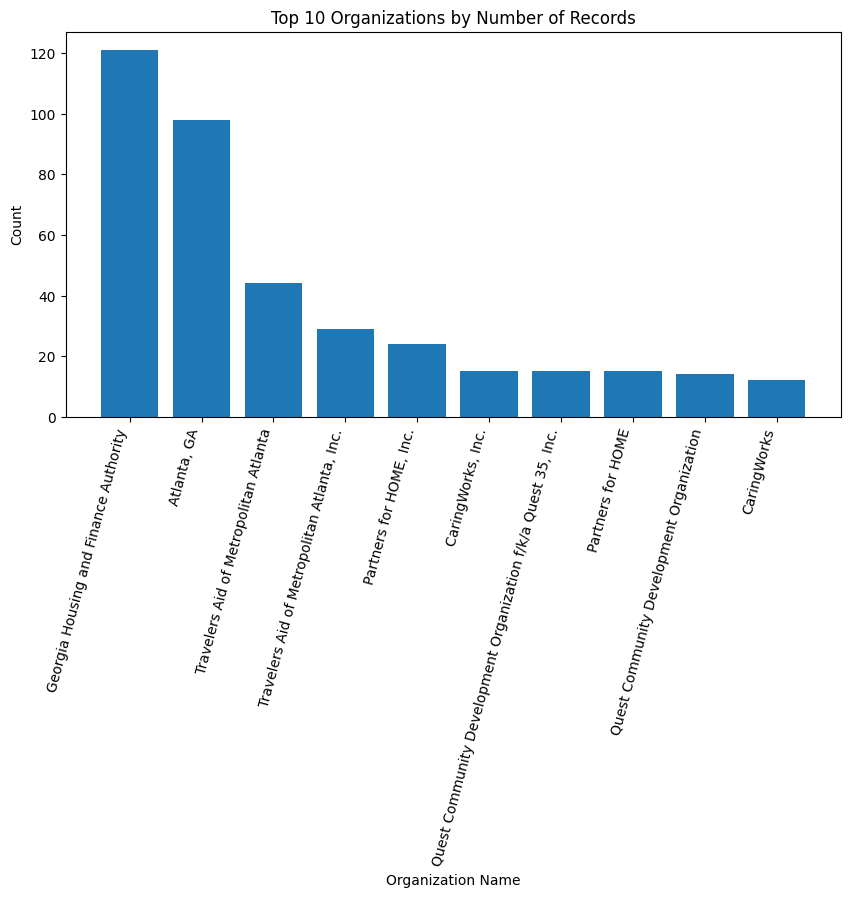

In [40]:
import matplotlib.pyplot as plt

def visual1():
    top_orgs = df["Organization Name"].value_counts().head(10) #value.counts counts how many times each unique value appears in the Organization Name column

    plt.figure(figsize=(10, 5)) #10x5 figure for the bar chart

    plt.bar(top_orgs.index, top_orgs.values) # create a bar chart with the organization names on the x-axis and their corresponding counts on the y-axis

    plt.xticks(rotation=75, ha="right") #rotate x-axis labels 75 degrees and align them to the right for better readability, especially if org names are long

    plt.title("Top 10 Organizations by Number of Records")
    plt.xlabel("Organization Name")
    plt.ylabel("Count")

    plt.tight_layout()
    plt.savefig("bar_chart.png")
    plt.show()

############ Function Call ############
visual1()

### Visualization 1 Explanation
This visualization shows the top 10 organizations by number of records in the dataset. We did this to compare which organizations appear most often and may be receiving funding more frequently. The x-axis lists organization names, and the y-axis shows the count of records. Taller bars represent organizations with more awards or entries. This makes it easier to compare organizations quickly than reading raw counts in a table.

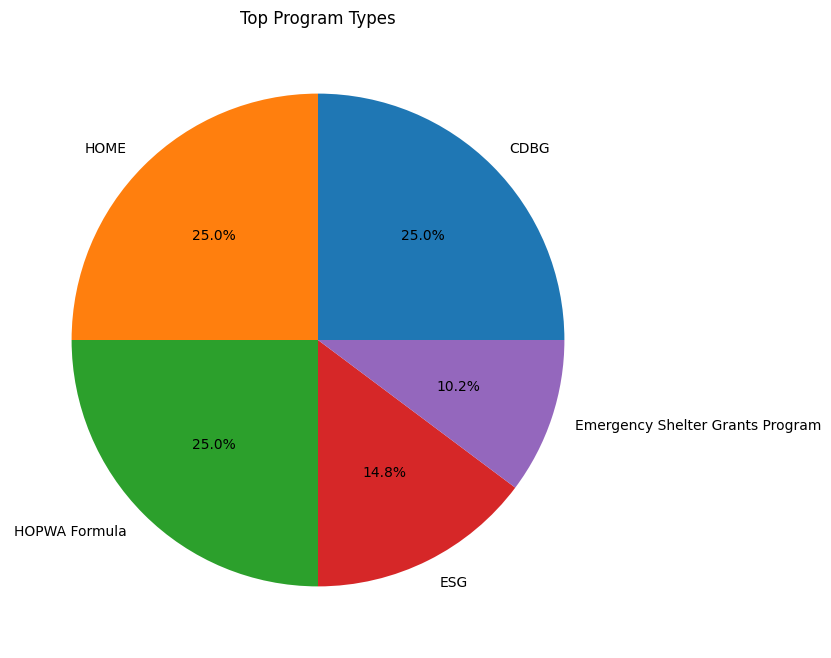

In [41]:
def visual2():
    program_counts = df["Program Name & Type"].value_counts().head(5)

    plt.figure(figsize=(8, 8))

    plt.pie(program_counts.values, labels=program_counts.index, autopct="%1.1f%%")

    plt.title("Top Program Types")

    plt.savefig("pie_chart.png")
    plt.show()


############ Function Call ############
visual2()

### Visualization 2 Explanation
This visualization shows the top 5 program types based on how often they appear in the dataset. We did this to understand how awards are distributed across major funding categories. Each slice represents one program type, and the percentage labels show its share of the total. Larger slices mean that program type appears more often. This gives a quick summary of which programs make up the largest portions of the dataset.

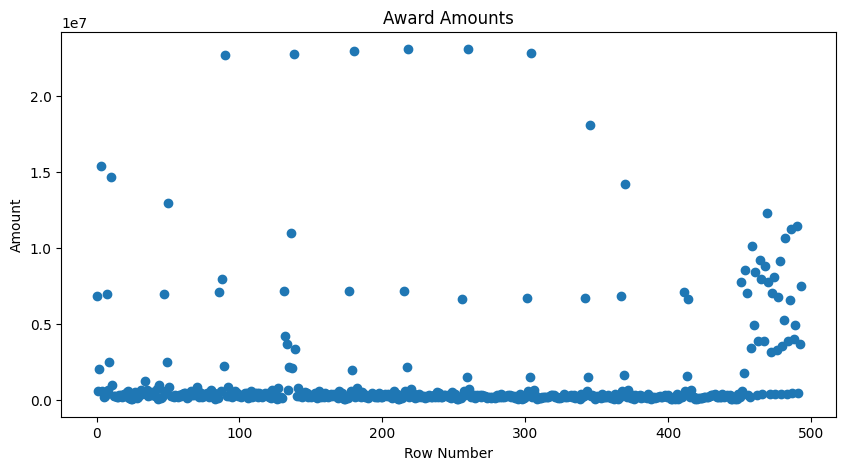

In [42]:
def visual3():
    plt.figure(figsize=(10, 5))

    plt.scatter(range(len(df)), df["Amount"])

    plt.title("Award Amounts")
    plt.xlabel("Row Number")
    plt.ylabel("Amount")

    plt.savefig("scatter_plot.png")
    plt.show()


############ Function Call ############
visual3()

### Visualization 3 Explanation
This visualization shows every award amount in the dataset as an individual point. We did this to examine the spread and variation of funding values across all records. The x-axis is the row number, and the y-axis is the award amount. Higher points represent larger awards, while lower points represent smaller awards. This helps identify clusters, gaps, and possible outliers in funding amounts.

# Cited Sources

If you used any additional sources to complete your Data Analysis section, list them here:


*   Example Module Documentation
*   Example Stack Overflow Assistance



# Submission

Prior to submitting your notebook to Gradescope, be sure to <b>run all functions within this file</b>. We will not run your functions ourselves, so we must see your outputs within this file in order to receive full credit.


Presentation Slides:https://docs.google.com/presentation/d/1ePjktmshvte72yZLasBtIVjsomiPVcyJ-vH7QnkahB8/edit?usp=sharing
 
